# A/B Testing for Website Optimization

**Internship Project: Internee.pk**

## 1. Introduction and Business Context
**Objective:** Test whether a homepage variation converts visitors at a different rate than the current homepage.

**Scenario (hypothetical):** Control = the current internee.pk homepage, which shows two competing buttons ("Our Job Portal" and "Dashboard") in the hero section. Treatment = a *proposed* variation with **one primary button**. The public dataset did not test this design, so the scenario is illustrative.

**Data note:** Internee.pk analytics were not accessible, so a public A/B dataset from Kaggle was used. Results are **not** actual internee.pk res
!lts.

![Current homepage](homepage_control.png)

| Metric | Type | Status |
|---|---|---|
| Conversion rate | Primary | Analyzed |
| Bounce rate | Secondary | Not in dataset |ut.

# data dictionary

### Data Dictionary
| Column | Description |
|---|---|
| user_id | Unique visitor ID |
| timestamp | Visit time (Jan 2 to Jan 24, 2017) |
| group | control / treatment |
| landing_page | old_page / new_page |
| converted | 1 = converted, 0 = did not |

# Setup

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
from scipy.stats import chisquare
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

ALPHA = 0.05
alpha = ALPHA
COLORS = {"control": "#4C78A8", "treatment": "#F58518"}  # same colors in every chart
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

#  Load the data

In [2]:
df = pd.read_csv("ab_data.csv")
display(df.head())

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [3]:
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Unique users:", df["user_id"].nunique())
print("Date range:", df["timestamp"].min()[:10], "to", df["timestamp"].max()[:10])
display(df.describe())


Shape: (294478, 5)
Missing values: 0
Unique users: 290584
Date range: 2017-01-02 to 2017-01-24


,user_id,converted
count,294478.000000,294478.000000
mean,787974.124733,0.119659
std,91210.823776,0.324563
min,630000.000000,0.000000
25%,709032.250000,0.000000
50%,787933.500000,0.000000
75%,866911.750000,0.000000
max,945999.000000,1.000000


# Data Quality Checks

In [4]:
print("Valid 'converted' values:", df["converted"].unique())
print("Group labels:", df["group"].unique())
print("Landing pages:", df["landing_page"].unique())
print("Full duplicate rows:", df.duplicated().sum())
print("Duplicate user_ids:", df["user_id"].duplicated().sum())
print("\nGroup vs landing page (off-diagonal cells are mismatches):")
display(pd.crosstab(df["group"], df["landing_page"], margins=True))

Valid 'converted' values: [0 1]
Group labels: ['control' 'treatment']
Landing pages: ['old_page' 'new_page']
Full duplicate rows: 0
Duplicate user_ids: 3894

Group vs landing page (off-diagonal cells are mismatches):


landing_page,new_page,old_page,All
group,,,
control,1928,145274,147202
treatment,145311,1965,147276
All,147239,147239,294478


# Data Cleaning  

In [5]:
ok = ((df["group"] == "control") & (df["landing_page"] == "old_page")) | \
     ((df["group"] == "treatment") & (df["landing_page"] == "new_page"))
step1 = df[ok]
df_clean = step1.drop_duplicates(subset="user_id", keep="first").copy()
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"])
df_clean["date"] = df_clean["timestamp"].dt.date

display(pd.DataFrame({
    "Step": ["Raw rows", "Mismatched group/page rows removed",
             "Duplicate users removed", "Final clean rows"],
    "Rows": [len(df), int((~ok).sum()), len(step1) - len(df_clean), len(df_clean)]}))
assert df_clean["user_id"].is_unique

,Step,Rows
0,Raw rows,294478
1,Mismatched group/page rows removed,3893
2,Duplicate users removed,1
3,Final clean rows,290584


# Experiment Validity

SRM check p-value: 0.947 -> split is balanced


,users,conversions,conversion_rate
group,,,
control,145274,17489,0.1204
treatment,145310,17264,0.1188


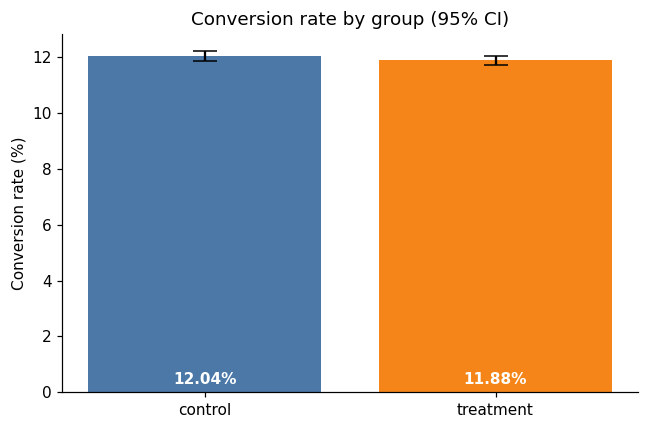

In [6]:
group_n = df_clean["group"].value_counts().reindex(["control", "treatment"])
srm_p = chisquare(group_n).pvalue
print(f"SRM check p-value: {srm_p:.3f} -> " +
      ("split is balanced" if srm_p > 0.01 else "WARNING: possible split problem"))

summary = (df_clean.groupby("group")["converted"]
           .agg(users="count", conversions="sum", conversion_rate="mean")
           .reindex(["control", "treatment"]))
display(summary.round(4))

rates = summary["conversion_rate"] * 100
err = 1.96 * np.sqrt(summary["conversion_rate"] * (1 - summary["conversion_rate"]) / summary["users"]) * 100
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(rates.index, rates, yerr=err, capsize=8, color=[COLORS[g] for g in rates.index])
ax.set_ylabel("Conversion rate (%)"); ax.set_title("Conversion rate by group (95% CI)")
for i, v in enumerate(rates):
    ax.text(i, 0.3, f"{v:.2f}%", ha="center", color="white", fontweight="bold")
plt.tight_layout(); plt.show()

# Metrics + Confidence Intervals

In [7]:
control = df_clean[df_clean['group'] == 'control']['converted']
treatment = df_clean[df_clean['group'] == 'treatment']['converted']

n_c, x_c = len(control), control.sum()
n_t, x_t = len(treatment), treatment.sum()
p_c, p_t = x_c/n_c, x_t/n_t

# Core metrics
abs_diff_pp = (p_t - p_c) * 100          # percentage points
rel_lift    = (p_t - p_c) / p_c * 100    # relative % change

print(f"Control conversion rate:    {p_c*100:.3f}%  ({x_c} conversions / {n_c} users)")
print(f"Treatment conversion rate:  {p_t*100:.3f}%  ({x_t} conversions / {n_t} users)")
print(f"Absolute difference:  {abs_diff_pp:+.3f} percentage points")
print(f"Relative lift:        {rel_lift:+.2f}%  (estimate implied by the rate difference, not an observed causal count)")

# 95% CI for each rate:  p ± 1.96 * sqrt(p(1-p)/n)
z = 1.96
se_c = np.sqrt(p_c * (1 - p_c) / n_c)
se_t = np.sqrt(p_t * (1 - p_t) / n_t)
print(f"\nControl 95% CI:    [{100*(p_c - z*se_c):.3f}%, {100*(p_c + z*se_c):.3f}%]")
print(f"Treatment 95% CI:  [{100*(p_t - z*se_t):.3f}%, {100*(p_t + z*se_t):.3f}%]")

# 95% CI for the DIFFERENCE (unpooled SE)
se_diff = np.sqrt(se_c**2 + se_t**2)
lo, hi = 100*(p_t - p_c - z*se_diff), 100*(p_t - p_c + z*se_diff)
print(f"\nDifference 95% CI: [{lo:.3f}, {hi:+.3f}] percentage points")

Control conversion rate:    12.039%  (17489 conversions / 145274 users)
Treatment conversion rate:  11.881%  (17264 conversions / 145310 users)
Absolute difference:  -0.158 percentage points
Relative lift:        -1.31%  (estimate implied by the rate difference, not an observed causal count)

Control 95% CI:    [11.871%, 12.206%]
Treatment 95% CI:  [11.714%, 12.047%]

Difference 95% CI: [-0.394, +0.078] percentage points


#  Hypothesis Testing (Two-Proportion Z-Test)

## Hypothesis and Decision Rule
- **H0:** The one-button page has the same conversion rate as the current page.
- **H1:** The conversion rates are different.
- **Test:** two-sided two-proportion z-test, alpha = 0.05
- **Decision rule:** Switch only if the new page is significantly better (p < 0.05 and a positive difference).

In [8]:
# H0: p_control = p_treatment   (conversion rates are equal)
# H1: p_control ≠ p_treatment   (conversion rates differ)
alpha = 0.05

# Pooled proportion and pooled SE (valid under H0, large samples, independent obs.)
p_pool = (x_c + x_t) / (n_c + n_t)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1/n_c + 1/n_t))

z_stat = (p_t - p_c) / se_pool
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(f"Null hypothesis H0:        p_control = p_treatment")
print(f"Alternative H1:          p_control ≠ p_treatment  (two-sided)")
print(f"Significance level:      alpha = {alpha}")
print(f"Pooled conversion rate:  {p_pool*100:.3f}%")
print(f"Z-statistic:             {z_stat:.4f}")
print(f"P-value:                 {p_value:.4f}")

if p_value < alpha:
    print("\nResult: p-value < 0.05 → Reject H0.")
    print("There is statistical evidence of a difference between the two pages.")
else:
    print("\nResult: p-value >= 0.05 → Fail to reject H0.")
    print("There is INSUFFICIENT evidence of a difference between the pages.")
    print("This does NOT prove the pages are equal — it means the data cannot")
    print("distinguish them at the 5% significance level.")

Null hypothesis H0:        p_control = p_treatment
Alternative H1:          p_control ≠ p_treatment  (two-sided)
Significance level:      alpha = 0.05
Pooled conversion rate:  11.960%
Z-statistic:             -1.3109
P-value:                 0.1899

Result: p-value >= 0.05 → Fail to reject H0.
There is INSUFFICIENT evidence of a difference between the pages.
This does NOT prove the pages are equal — it means the data cannot
distinguish them at the 5% significance level.


#  Results Visualization

In [9]:
G = ["control", "treatment"]
n  = df_clean.groupby("group")["converted"].count().reindex(G)
x  = df_clean.groupby("group")["converted"].sum().reindex(G)
p  = x / n
se = np.sqrt(p * (1 - p) / n)
diff    = (p["treatment"] - p["control"]) * 100
se_diff = np.sqrt(se["control"]**2 + se["treatment"]**2) * 100
ci_lo, ci_hi = diff - 1.96 * se_diff, diff + 1.96 * se_diff

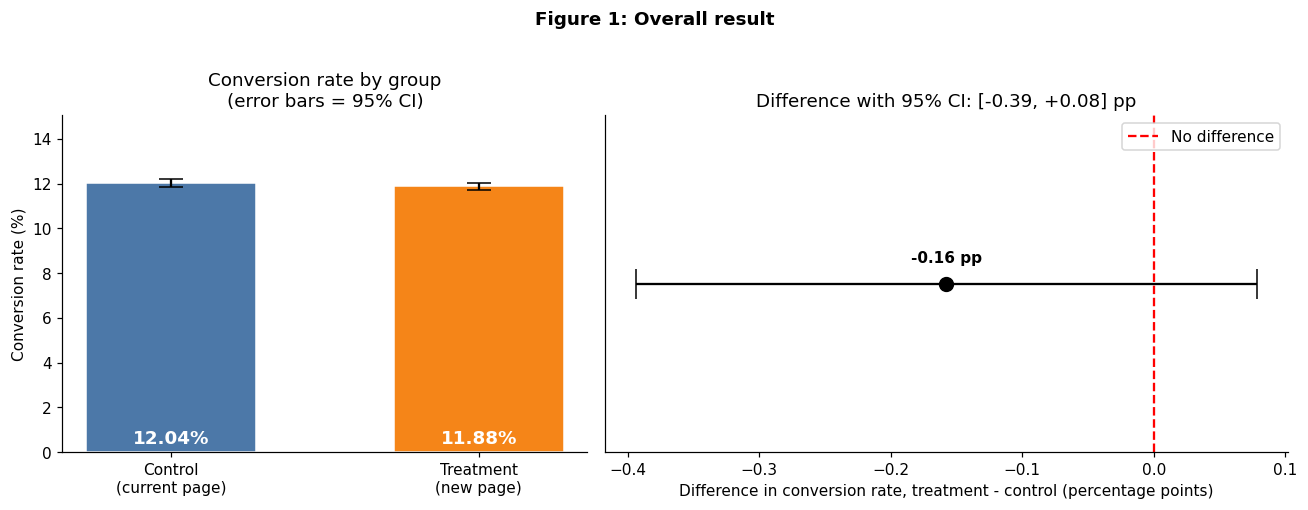

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
bars = ax[0].bar(G, p * 100, yerr=1.96 * se * 100, capsize=8, width=0.55,
                 color=[COLORS[g] for g in G], edgecolor="white")
for b, g in zip(bars, G):
    ax[0].text(b.get_x() + b.get_width()/2, 0.4, f"{p[g]*100:.2f}%",
               ha="center", color="white", fontsize=12, fontweight="bold")
ax[0].set_ylim(0, p.max() * 100 * 1.25)
ax[0].set_ylabel("Conversion rate (%)")
ax[0].set_title("Conversion rate by group\n(error bars = 95% CI)")
ax[0].set_xticks(range(2)); ax[0].set_xticklabels(["Control\n(current page)", "Treatment\n(new page)"])

ax[1].errorbar(diff, 0, xerr=[[diff - ci_lo], [ci_hi - diff]], fmt="o", color="black", capsize=10, markersize=9)
ax[1].axvline(0, color="red", linestyle="--", label="No difference")
ax[1].annotate(f"{diff:+.2f} pp", (diff, 0), textcoords="offset points", xytext=(0, 14), ha="center", fontweight="bold")
ax[1].set_yticks([]); ax[1].set_ylim(-1, 1)
ax[1].set_xlabel("Difference in conversion rate, treatment - control (percentage points)")
ax[1].set_title(f"Difference with 95% CI: [{ci_lo:+.2f}, {ci_hi:+.2f}] pp")
ax[1].legend(loc="upper right")
plt.suptitle("Figure 1: Overall result", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

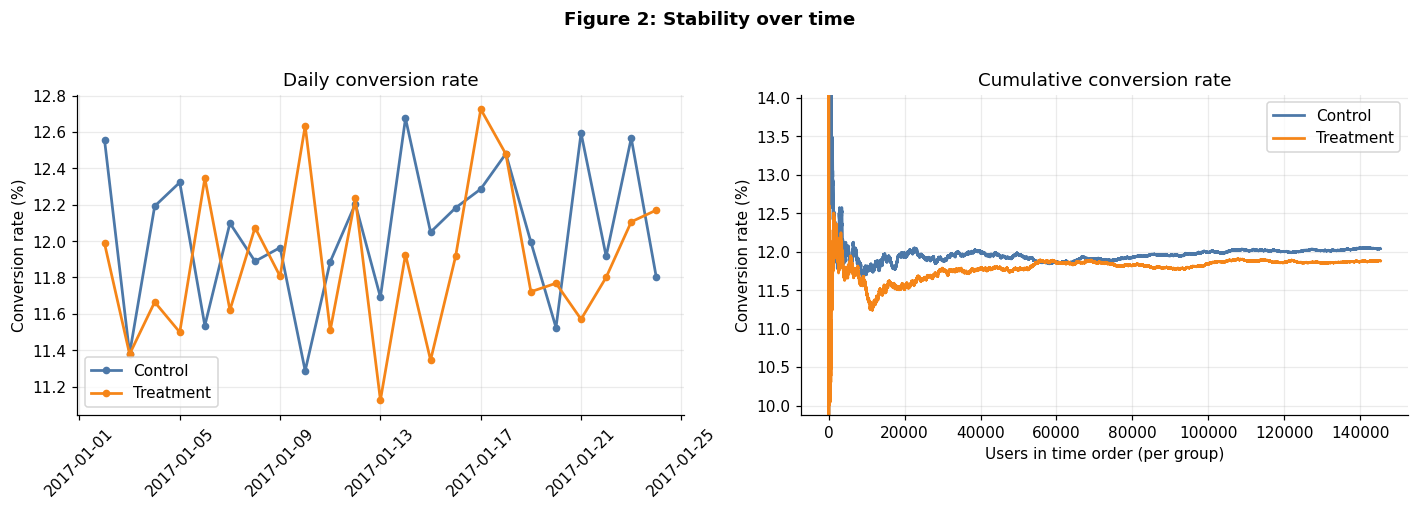

In [11]:
daily = df_clean.groupby(["date", "group"])["converted"].mean().unstack()[G] * 100
d = df_clean.sort_values("timestamp")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for g in G:
    ax[0].plot(daily.index, daily[g], marker="o", markersize=4, linewidth=1.8, color=COLORS[g], label=g.capitalize())
ax[0].set_title("Daily conversion rate"); ax[0].set_ylabel("Conversion rate (%)")
ax[0].tick_params(axis="x", rotation=45); ax[0].legend(); ax[0].grid(alpha=0.25)

for g in G:
    s = d.loc[d["group"] == g, "converted"].reset_index(drop=True)
    ax[1].plot(s.expanding().mean() * 100, linewidth=1.8, color=COLORS[g], label=g.capitalize())
ax[1].set_ylim(p.min() * 100 - 2, p.max() * 100 + 2)
ax[1].set_title("Cumulative conversion rate"); ax[1].set_xlabel("Users in time order (per group)")
ax[1].set_ylabel("Conversion rate (%)"); ax[1].legend(); ax[1].grid(alpha=0.25)
plt.suptitle("Figure 2: Stability over time", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

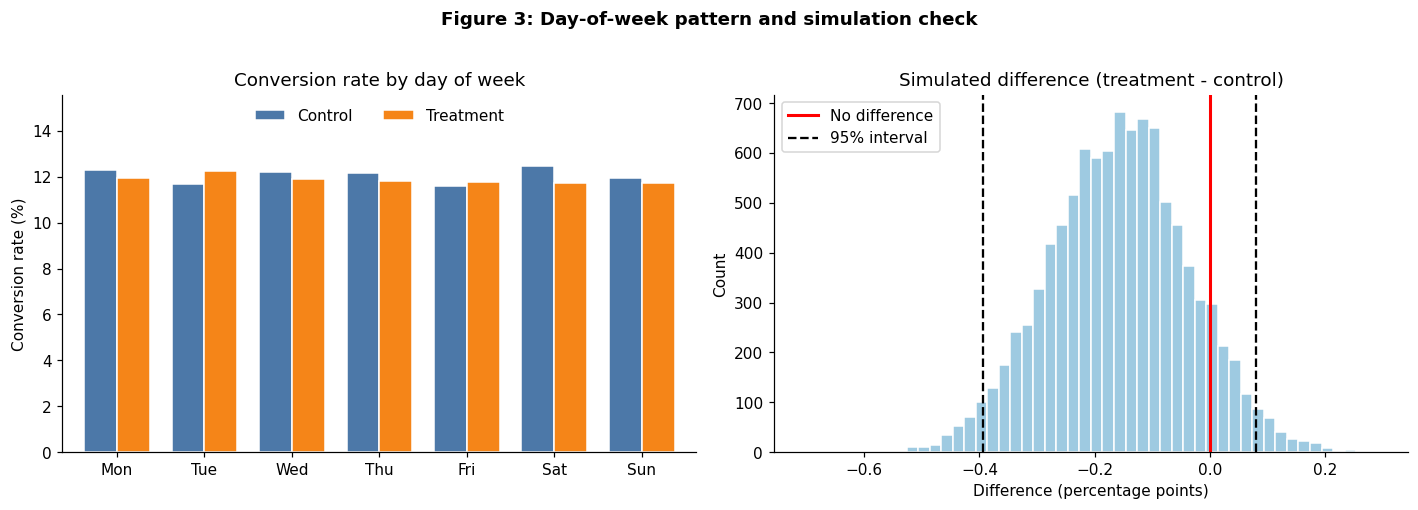

In [12]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
dow = (df_clean.assign(weekday=df_clean["timestamp"].dt.day_name())
       .groupby(["weekday","group"])["converted"].mean().unstack().reindex(order)[G] * 100)

rng = np.random.default_rng(42)
sim = (rng.binomial(n["treatment"], p["treatment"], 10000) / n["treatment"]
     - rng.binomial(n["control"],   p["control"],   10000) / n["control"]) * 100
sim_lo, sim_hi = np.percentile(sim, [2.5, 97.5])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dow.plot(kind="bar", ax=ax[0], width=0.75, color=[COLORS[g] for g in G], edgecolor="white")
ax[0].set_title("Conversion rate by day of week"); ax[0].set_xlabel(""); ax[0].set_ylabel("Conversion rate (%)")
ax[0].set_xticklabels([w[:3] for w in order], rotation=0)
ax[0].set_ylim(0, dow.max().max() * 1.25)
ax[0].legend(["Control", "Treatment"], loc="upper center", ncol=2, frameon=False)

ax[1].hist(sim, bins=50, color="#9ecae1", edgecolor="white")
ax[1].axvline(0, color="red", linewidth=2, label="No difference")
ax[1].axvline(sim_lo, color="black", linestyle="--", label="95% interval")
ax[1].axvline(sim_hi, color="black", linestyle="--")
ax[1].set_title("Simulated difference (treatment - control)")
ax[1].set_xlabel("Difference (percentage points)"); ax[1].set_ylabel("Count"); ax[1].legend()
plt.suptitle("Figure 3: Day-of-week pattern and simulation check", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

# Power

In [13]:
analysis = NormalIndPower()

# (a) Smallest lift this test could reliably detect (80% power, alpha = 0.05)
h = analysis.solve_power(effect_size=None, nobs1=n_c, alpha=ALPHA, power=0.8, ratio=n_t / n_c)
mde_pp = (np.sin(np.arcsin(np.sqrt(p_c)) + h / 2) ** 2 - p_c) * 100

# (b) Users per group needed to detect a 0.5 percentage-point lift (planning example)
need_n = analysis.solve_power(effect_size=proportion_effectsize(p_c + 0.005, p_c),
                              alpha=ALPHA, power=0.8, ratio=1)

print(f"Smallest lift this test could reliably detect: about {mde_pp:.2f} percentage points")
print(f"Users per group needed to detect a 0.5-point lift: {int(np.ceil(need_n)):,}")

Smallest lift this test could reliably detect: about 0.34 percentage points
Users per group needed to detect a 0.5-point lift: 67,673


**Interpretation:** The test had enough users to reliably detect a lift of about 0.34 percentage points
or more. The observed difference (-0.16 pp) is smaller and not significant, so the data suggests the new
page does not deliver a meaningful improvement. Smaller effects cannot be ruled out.
The 0.5-point example is a planning assumption, not an internee.pk target.

#   Conclusion 

## Conclusion & Recommendations
The new landing page showed a slightly lower conversion rate than the old page
(11.88% vs 12.04%, −0.16 pp), but the difference was **not statistically significant**
(z = −1.31, p = 0.19). The 95% CI for the difference [−0.39, +0.08] pp contains zero.


**Recommendation:** There is no evidence to justify switching to the new design.
Retain the current homepage, or run a follow-up experiment with a more substantially
redesigned variant and a pre-registered minimum detectable effect.

**Limitations:** The dataset contains no bounce-rate or engagement columns, so only
conversion rate could be analyzed; a live Internee.pk experiment should additionally
track CTA clicks and session engagement via Google Analytics events. Public proxy data (not live Internee.pk analytics); single binary outcome
(no engagement metrics); experiment period limited to ~3 weeks**.

In [14]:
# Export cleaned dataset for reproducibility
df_clean.to_csv('ab_data_cleaned.csv', index=False)
print("Cleaned dataset saved:", df_clean.shape)

Cleaned dataset saved: (290584, 6)


# Business recommendations

In [15]:
VISITORS = 100_000   # illustrative assumption
print(f"Change per {VISITORS:,} visitors: {abs_diff_pp/100*VISITORS:+.0f} conversions "
      f"(range {ci_lo/100*VISITORS:+.0f} to {ci_hi/100*VISITORS:+.0f})")

Change per 100,000 visitors: -158 conversions (range -394 to +78)


## Business Recommendations

**1. Decision (based on this test):** Do not switch to the new page. It converted slightly lower
(11.88% vs 12.04%), the difference is not statistically significant (p = 0.19), and the
confidence interval [-0.39, +0.08] pp includes zero. Keep the current page.

**2. Why this is reasonable:** The test was large enough to detect a lift of about 0.34 percentage
points, so a meaningful improvement is unlikely to have been missed. Switching would cost design and
development effort with no evidence of benefit.

**3. What to do next at internee.pk:**
- Test a **bolder change** (for example, one main call-to-action button), since small
  changes are hard to detect.
- Track **sign-up conversion, button clicks and bounce rate** in Google Analytics 4. Bounce rate was not
  available in this dataset.
- **Segment** results by device (mobile/desktop) and traffic source, because a design can help one
  group and hurt another.
- Decide the **sample size and duration in advance** and run for full weeks.

**4. Risks to watch:** A new design should not increase bounce rate or slow the page. Monitor these
as guardrail metrics.

**5. Important caveat:** These results come from a public dataset and describe that data only.
Internee.pk's real visitors may behave differently, so the recommendation must be confirmed with a live test.

# README.md

# A/B Testing for Website Optimization — Internship Project (Internee.pk)

## Overview
Analysis of an A/B test comparing an old vs. new landing page using a public
Kaggle dataset (https://www.kaggle.com/datasets/zhangluyuan/ab-testing).
Demonstrates the full workflow: data validation, cleaning, EDA, conversion metrics,
confidence intervals, and a two-proportion z-test.

## Key Result
No statistically significant difference in conversion rate
(control 12.04% vs treatment 11.88%, p = 0.19) → retain current design
or run a follow-up experiment.

## Files
- `A_B_Testing.ipynb` — full analysis notebook
- `ab_data.csv` — raw dataset (from Kaggle)
- `ab_data_cleaned.csv` — cleaned dataset (290,584 unique users)

## How to Run
1. Place `ab_data.csv` next to the notebook.
2. Run all cells top to bottom (Kernel → Restart & Run All).
Requirements: Python 3, pandas, numpy, matplotlib, seaborn, scipy.